In [144]:
import numpy as np
import scipy
import matplotlib.pyplot as plt

In [145]:
pi_t = 0.35368326100748115
tau_t = 0.7687676014665914
eta_t = 0.90
pi_d =  0.989163
pi_b = 1

m_dot_fR = 0.008726071272118822

A1 = 0.00318
A4 = 0.0005141364620689669
A8 = 0.0012745633749949147
M4 = 1
M8 = 1

In [146]:
tau_d = 1


In [147]:
pi_c_max = 18
pi_c_min = 7.5

rpm_max = 66000

Tt4_max = 1800

In [148]:
gamma = 1.4
Gamma = (2/(gamma+1))**((gamma+1)/(2*(gamma-1)))*np.sqrt(gamma)
Cp = 1004.5
R = 287
h = 4.45e+7

Alt_list = np.array([0,4000,8000,12000])
T0_list = np.array([288.15 ,262.15 ,236.23 ,216.65])
P0_list = np.array([101325 , 61640.235,35651 ,19330.405])
rho0_list = P0_list/(R*T0_list)
a0_list = np.sqrt(gamma*R*T0_list)



In [149]:
n = 300
Alt_size = Alt_list.size

M0 = np.linspace(0,2.5,n)
m_dot_f = np.linspace(.2,5,n) * m_dot_fR

M0, m_dot_f = np.meshgrid(M0,m_dot_f)

M0 = np.matrix.flatten(M0)
m_dot_f = np.matrix.flatten(m_dot_f)

#M0 = np.array([0.85])
#m_dot_f =  np.array([m_dot_fR]) 

j = 2

Alt = Alt_list[j]
T0 = T0_list[j]
P0 = P0_list[j]
rho0 = P0/(R*T0)
a0 = np.sqrt(gamma*R*T0)


Tt4_plot = np.empty(n**2)
rpm_plot = np.empty(n**2)
pi_c_plot = np.empty(n**2)
Thrust_plot = np.empty(n**2)
spill_plot = np.empty(n**2)


for i in range(M0.size):
    u0 = M0[i] * np.sqrt(gamma*R*T0)
    
    m_dot_no_spill = rho0 * u0 * A1
    
    tau_r = 1+(gamma-1)/2 * M0[i]**2
    pi_r = tau_r**(gamma/(gamma-1))
    
    Tt0 = T0 * tau_r
    Pt0 = P0 * pi_r
    
    Tt2 = Tt0
    Pt2 = Pt0 * pi_d
    
    def eta_c_fit(Tt4):
        x = Tt4/Tt2
        a = -2.3219 
        b = 1.7094 
        c = -0.2897 
        d = 0.0155
        return a + b*x + c*x**2 + d*x**3

    def corr_rpm_fit(pi_c):
        x = pi_c
        aa = 22352.47 
        bb = 3718.445 
        cc = -52.5576 
        dd = -1.0899
        return aa + bb*x + cc*x**2 + dd*x**3
    
    def _tau_c(Tt4):
        return 1+(Tt4/Tt0)*(1-tau_t)
    
    def _pi_c(Tt4):
        return  (1+eta_c_fit(Tt4)*(_tau_c(Tt4)-1))**(gamma/(gamma-1))
    
    def _m_dot(Tt4):
        return Gamma / np.sqrt(R) * A4 * (P0*pi_r*pi_d*_pi_c(Tt4)*pi_b)*1/(np.sqrt(Tt4))
    
    _mdotf = lambda Tt4: _m_dot(Tt4)*Cp*(Tt4 - _tau_c(Tt4) * Tt2)/h-m_dot_f[i]
    
    Tt4 = scipy.optimize.fsolve(_mdotf,900,maxfev=90000)
    
    
    tau_c = _tau_c(Tt4)
    pi_c = _pi_c(Tt4)
    #tau_b = tau_lambda/(tau_r * tau_d * tau_c)
    m_dot_air = _m_dot(Tt4)
    corr_rpm = corr_rpm_fit(pi_c)# * np.sqrt(Tt0/T0)
    
    eta_c = eta_c_fit(Tt4)
    
    Tt4_plot[i] = Tt4
    rpm_plot[i] = corr_rpm
    pi_c_plot[i] = pi_c
    
    
    if Tt4 > Tt4_max or Tt4 <= Tt0 or Tt4 == 900:
        Tt4_plot[i] = np.nan
        pi_c_plot[i] = np.nan
        rpm_plot[i] = np.nan
        continue
    
    if pi_c > pi_c_max or pi_c < pi_c_min:
        Tt4_plot[i] = np.nan
        pi_c_plot[i] = np.nan
        rpm_plot[i] = np.nan
        continue
    
    if corr_rpm > rpm_max:
        Tt4_plot[i] = np.nan
        pi_c_plot[i] = np.nan
        rpm_plot[i] = np.nan
        continue
    

C:\Users\rjk12\AppData\Local\Temp\ipykernel_34120\3868892061.py:84: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  Tt4_plot[i] = Tt4
C:\Users\rjk12\AppData\Local\Temp\ipykernel_34120\3868892061.py:85: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  rpm_plot[i] = corr_rpm
C:\Users\rjk12\AppData\Local\Temp\ipykernel_34120\3868892061.py:86: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  pi_c_plot[i] = pi_c


C:\Users\rjk12\AppData\Local\Temp\ipykernel_34120\3868892061.py:73: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  Tt4 = scipy.optimize.fsolve(_mdotf,900,maxfev=90000)


In [150]:
Tt0

531.5174999999999

In [151]:
Tt4_plot = np.reshape(Tt4_plot,(n,n))
rpm_plot = np.reshape(rpm_plot,(n,n))
pi_c_plot = np.reshape(pi_c_plot,(n,n))
M0 = np.reshape(M0,(n,n))
m_dot_f = np.reshape(m_dot_f,(n,n))
#plt.contourf(M0,m_dot_f,Tt4_plot)

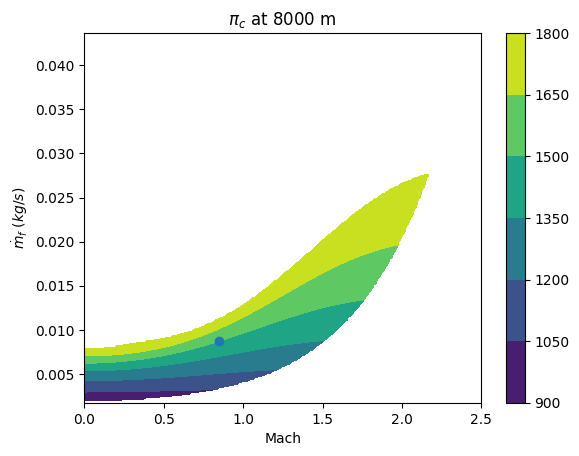

<Figure size 640x480 with 0 Axes>

In [156]:
fig = plt.figure(1)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,Tt4_plot)
fig.colorbar(cp)

if j == 2:
    ax.scatter(0.85,m_dot_fR)
    
ax.set_title(r'$\pi_c$ at {} m '.format(Alt_list[j]))
ax.set_xlabel('Mach')
ax.set_ylabel(r'$\dot{m}_f \ (kg/s)$')
plt.show()

plt.savefig(r'pi_c_at_{}_m.png'.format(Alt_list[j]), dpi=1200)

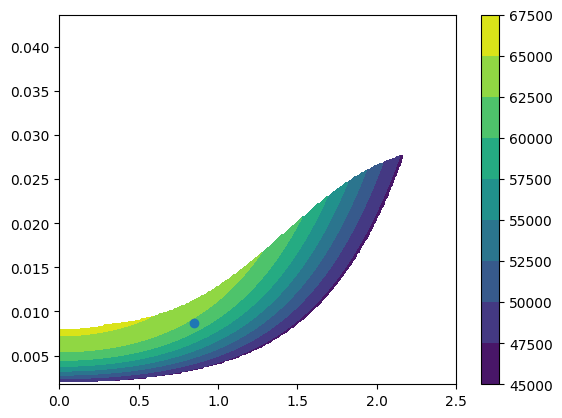

In [153]:
fig = plt.figure(2)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,rpm_plot,cmap='viridis')
if j == 2:
    ax.scatter(0.85,m_dot_fR)
fig.colorbar(cp)
plt.show()

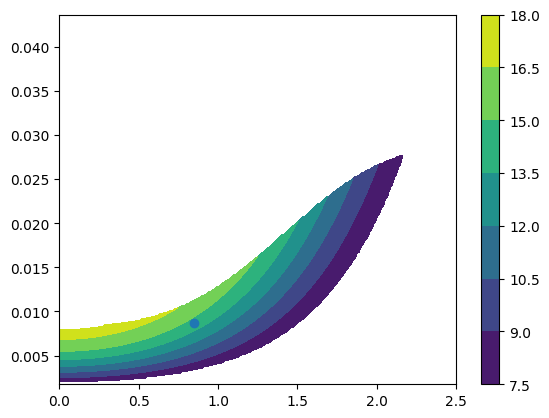

In [154]:
fig = plt.figure(3)
ax = plt.axes()
cp = ax.contourf(M0,m_dot_f,pi_c_plot)

if j == 2:
    ax.scatter(0.85,m_dot_fR)
fig.colorbar(cp)
plt.show()